# D1_05 EDA 체크리스트

> **오늘 질문:** 이 데이터를 믿어도 될까? 고장은 어디서 많이 나나?

4교시에 만든 분석 테이블을 **EDA 체크리스트 10단계** 순서대로 점검합니다.

| # | 확인 항목 | # | 확인 항목 |
|---|---|---|---|
| 1 | 크기 `shape` | 6 | 기술통계 `describe()` |
| 2 | 타입 `dtypes` | 7 | 범주 빈도 `value_counts()` |
| 3 | 결측 `isna().sum()` | 8 | 타깃 분포: 고장 비율 |
| 4 | 중복 `duplicated()` | 9 | 그룹 비교: 설비·등급별 |
| 5 | 범위: 가능한 값인가 | 10 | 시간 추이 |

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 4교시 결과물과 같은 분석 테이블
df = pd.read_parquet("../../data/analysis_table.parquet")

## 1~2. 크기와 타입 ✍️

In [2]:
# 힌트: df.shape, df.dtypes
print(df.shape)
df.dtypes

(10015, 20)


record_id                int64
timestamp       datetime64[ns]
equip_id                object
product_id              object
grade                   object
air_temp               float64
process_temp           float64
rpm                      int64
torque                 float64
tool_wear                int64
vibration              float64
failure                  int64
twf                      int64
hdf                      int64
pwf                      int64
osf                      int64
rnf                      int64
line                    object
maker                   object
install_year             int64
dtype: object

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   record_id     10015 non-null  int64         
 1   timestamp     10015 non-null  datetime64[ns]
 2   equip_id      10015 non-null  object        
 3   product_id    10015 non-null  object        
 4   grade         10015 non-null  object        
 5   air_temp      10015 non-null  float64       
 6   process_temp  10015 non-null  float64       
 7   rpm           10015 non-null  int64         
 8   torque        9965 non-null   float64       
 9   tool_wear     10015 non-null  int64         
 10  vibration     10015 non-null  float64       
 11  failure       10015 non-null  int64         
 12  twf           10015 non-null  int64         
 13  hdf           10015 non-null  int64         
 14  pwf           10015 non-null  int64         
 15  osf           10015 non-null  int64 

## 3. 결측 ✍️

결측이 몇 개인지보다 **어디에 몰려 있는지**가 중요합니다.

In [5]:
# 힌트: df.isna().sum()
df.isna().sum()

record_id        0
timestamp        0
equip_id         0
product_id       0
grade            0
air_temp         0
process_temp     0
rpm              0
torque          50
tool_wear        0
vibration        0
failure          0
twf              0
hdf              0
pwf              0
osf              0
rnf              0
line             0
maker            0
install_year     0
dtype: int64

결측이 있는 행만 골라 특정 설비나 시간에 몰려 있는지 봅니다.

In [8]:
# 힌트: df[ 조건 ], df[df["컬럼"].isna()]
missing = df[ df['torque'].isna() ] # torque  50 <-- 결측치 50개
print(missing.shape)
display(missing.head(2)) # df는 display 로 출력하면 이쁘게 출력됨.
missing['equip_id'].value_counts()

(50, 20)


,record_id,timestamp,equip_id,product_id,grade,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure,twf,hdf,pwf,osf,rnf,line,maker,install_year
52,53,2025-01-01 12:28:48,MC-07,H29466,H,25.7,35.9,1497,NaN,147,1.71,0,0,0,0,0,0,L2,C사,2022
270,271,2025-01-03 16:48:00,MC-07,H29684,H,24.9,34.9,1520,NaN,51,1.88,0,0,0,0,0,0,L2,C사,2022


equip_id
MC-07    6
MC-01    6
MC-10    6
MC-05    6
MC-03    6
MC-06    5
MC-08    5
MC-09    5
MC-04    3
MC-02    2
Name: count, dtype: int64

특정 설비에 몰려 있지 않으면, 이번에는 **중앙값으로 채웁니다.**

In [10]:
df['torque'].median() # 40.1

40.1

In [9]:
# 힌트: df["컬럼"].fillna(값), fill : 채운다, na : 결측치
df['torque'] = df['torque'].fillna( df['torque'].median() ) # i = i + 1

## 4. 중복 ✍️

완전히 같은 행이 몇 개인지 세고, 지운 뒤 행 수를 다시 확인합니다.

In [12]:
# 힌트: df.duplicated().sum(), df.drop_duplicates()
print(f"중복 행: {df.duplicated().sum()}") # df.중복_데이터().합계()
df = df.drop_duplicates() # df = df.중복_데이터_삭제()
print(f"정리 후: {len(df)}행")

중복 행: 15
정리 후: 10000행


## 5~6. 범위와 기술통계 ✍️

최솟값·최댓값이 물리적으로 가능한 값인지 봅니다. (온도는 ℃, 회전수는 rpm, 토크는 Nm, 공구 마모는 분, 진동은 mm/s)

In [14]:
# 힌트: df.describe(), describe : 기술(기록)하다, 설명하다
df.describe().round(1)

,record_id,timestamp,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure,twf,hdf,pwf,osf,rnf,install_year
count,10000.0,10000,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,5000.5,2025-02-19 23:52:48,26.9,36.9,1538.8,40.0,108.0,2.1,0.0,0.0,0.0,0.0,0.0,0.0,2018.5
min,1.0,2025-01-01 00:00:00,22.2,32.6,1168.0,3.8,0.0,1.1,0.0,0.0,0.0,0.0,0.0,0.0,2012.0
25%,2500.8,2025-01-25 23:56:24,25.2,35.7,1423.0,33.3,53.0,1.9,0.0,0.0,0.0,0.0,0.0,0.0,2018.0
50%,5000.5,2025-02-19 23:52:48,27.0,37.0,1503.0,40.1,108.0,2.1,0.0,0.0,0.0,0.0,0.0,0.0,2020.0
75%,7500.2,2025-03-16 23:49:12,28.4,38.0,1612.0,46.7,162.0,2.3,0.0,0.0,0.0,0.0,0.0,0.0,2021.0
max,10000.0,2025-04-10 23:45:36,31.4,40.7,2886.0,76.6,253.0,3.4,1.0,1.0,1.0,1.0,1.0,1.0,2022.0
std,2886.9,NaN,2.0,1.5,179.3,9.9,63.7,0.3,0.2,0.1,0.1,0.1,0.1,0.0,3.3


**Q1.** 물리적으로 이상해 보이는 값이 있나요? 평균과 중앙값(50%)이 크게 다른 컬럼은?

> 답:


## 7~8. 범주 빈도와 고장 비율 ✍️

In [17]:
# 힌트: df["범주형_컬럼"].value_counts(), df["컬럼"].mean()
print(df["grade"].value_counts()) # 범주형 컬럼의 갯수 세기
print(f"고장 비율: {df['failure'].mean():.1%}") # 소수점 첫째 자리 %로 보여라.

grade
L    6000
M    2997
H    1003
Name: count, dtype: int64
고장 비율: 3.4%


## 9. 그룹 비교 ✍️

불량률은 **분모(생산 건수)와 함께** 봅니다. `agg`로 건수·고장 수·고장률을 한 번에 구합니다.

In [21]:
# 힌트: df.groupby(["컬럼1", "컬럼2"])["failure"].agg(["count", "sum", "mean"])
df.groupby(["equip_id", "install_year"])['failure'].agg(["count", "sum", "mean"]) # 그룹별 종합 통계

,,count,sum,mean
equip_id,install_year,,,
MC-01,2019,962,28,0.029106
MC-02,2020,996,24,0.024096
MC-03,2012,1016,62,0.061024
MC-04,2021,989,28,0.028311
MC-05,2018,954,30,0.031447
MC-06,2019,962,27,0.028067
MC-07,2022,1046,29,0.027725
MC-08,2013,1070,54,0.050467
MC-09,2020,1005,29,0.028856


In [22]:
df.groupby("grade")['failure'].agg(["count", "sum", "mean"]).round(3)

,count,sum,mean
grade,,,
H,1003,21,0.021
L,6000,235,0.039
M,2997,83,0.028


## 10. 시간 추이 ✍️

`resample("W", on="timestamp")`는 일시를 주 단위로 묶습니다.

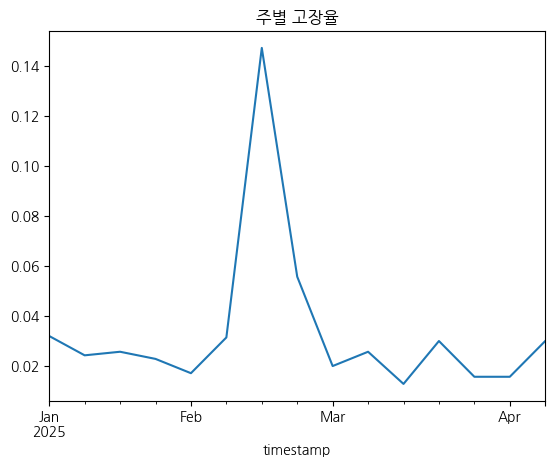

In [23]:
# 힌트: df.resample("W", on="timestamp")["컬럼"].mean().plot()
df.resample("W", on="timestamp")["failure"].mean().plot()
plt.title("주별 고장율")
plt.show()

고장률이 갑자기 튄 주가 있습니다. 그 주(2월 10~16일)의 고장 유형을 세어 봅니다. 📋

In [24]:
# 2월10일 이상 ~ 2월16일까지(2월17일 미만)
week = df[ (df["timestamp"] >= "2025-02-10") & (df["timestamp"] < "2025-02-17") ]
print(f"이 주의 고장: {week['failure'].sum()}건 / 전체 기간 고장: {df['failure'].sum()}건")
cols = ["twf", "hdf", "pwf", "osf", "rnf"] # 리스트로 관심 컬럼들 정의
week[ cols ].sum()

이 주의 고장: 103건 / 전체 기간 고장: 339건


twf     5
hdf    86
pwf    10
osf     8
rnf     0
dtype: int64

**Q2.** 고장률이 튄 주에는 어떤 고장 유형이 몰려 있나요? 현장이라면 무엇을 먼저 확인하겠습니까?

> 답: 열 방출 고장(HDF)이 86건. 온도가 높았다. --> 냉각 설비 등 점검


## 정리 💬

**Q3.** 고장률이 눈에 띄게 높은 설비는 어디인가요? 설비 정보에서 공통점을 찾아보세요.

> 답: MC-03  2012  1016  62  0.061024 <-- 다른 설비(0.02)의 약 3배. 2012 설치된 설비로 노후화가 원인으로 추정

**Q4.** 결측과 중복을 처리하지 않고 설비별 고장률을 냈다면 무엇이 달라졌을까요?

> 답:
